# 07 · Backtest, risk and interpretation

Do the forecasts make money after costs, and do they give more reliable risk estimates (RQ4)? (`scripts/run_backtest.py`, `scripts/run_shap.py`)

- **Timing:** a position chosen at the close of day *t* is held to the next close. It earns the next day's return plus carry: the interest differential for the days held, weekends included.
- **Costs:** changing a position costs half the pair's assumed bid-ask spread per unit traded. Every strategy is also run at twice the cost.
- **Signals:** flat, always long, carry (long the higher-yielding currency), 12-month time series momentum, and the direction forecasts of logistic regression, random forest, LightGBM and the MLP. Each model also has a `_confident` version that only trades when its forecast is further from 50% than its median distance over the past year of forecasts.
- **Sizing:** one unit, or volatility targeting (`vt_*`): each position is sized to a 10% annual volatility using a model's variance forecast (naive, EWMA, HAR-RV or LightGBM), with leverage capped at 3.
- **Portfolio:** the equal-weight average of the seven pairs. With volatility targeting each pair carries the same forecast risk, so it is an equal-risk portfolio.
- **Value at Risk:** 99% one-day Value at Risk from every volatility model, as normal quantiles and as filtered historical simulation, checked with the Kupiec and Christoffersen tests.
- **SHAP:** what drives the LightGBM forecasts.

Test period: January 2012 to October 2026.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fxml import viz
from fxml.config import load_config

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
strategies = pd.read_csv(tables / "backtest_strategies.csv")
breakdown = pd.read_csv(tables / "backtest_breakdown.csv")
targeting = pd.read_csv(tables / "backtest_risk_targeting.csv")
var = pd.read_csv(tables / "risk_var.csv")
shap = pd.read_csv(tables / "shap_lightgbm.csv")
daily = pd.read_parquet(cfg.paths.reports / "predictions" / "backtest.parquet")
pairs = list(cfg.pairs)
portfolio = strategies[strategies.pair == "portfolio"].set_index(["signal", "sizing"])
pd.set_option("display.precision", 3)
BASELINE_SIGNALS = ["long", "carry", "momentum"]
MODEL_SIGNALS = ["logistic_l2", "random_forest", "lightgbm", "mlp"]
SIZINGS = ["unit", "vt_naive", "vt_ewma", "vt_har", "vt_lightgbm"]

## Equal-risk portfolio

Net of costs. `t_stat` and `p_value` test whether the mean daily return differs from zero (Newey–West standard errors). With 55 strategies, about three would pass p < 0.05 by chance alone.

In [2]:
cols = ["ann_return", "ann_vol", "sharpe", "gross_sharpe", "sharpe_2x_costs", "max_drawdown",
        "turnover", "cost_drag", "t_stat", "p_value"]
portfolio.loc[[(s, "unit") for s in BASELINE_SIGNALS + MODEL_SIGNALS] +
              [(f"{s}_confident", "unit") for s in MODEL_SIGNALS], cols]

,,ann_return,ann_vol,sharpe,gross_sharpe,sharpe_2x_costs,max_drawdown,turnover,cost_drag,t_stat,p_value
signal,sizing,,,,,,,,,,
long,unit,0.005,0.032,0.151,1.511e-01,0.151,-0.132,0.066,4.092e-06,0.602,0.547
carry,unit,0.011,0.045,0.245,2.463e-01,0.243,-0.115,0.817,7.010e-05,1.009,0.313
momentum,unit,-0.001,0.052,-0.021,6.380e-04,-0.042,-0.153,17.418,1.114e-03,-0.082,0.934
logistic_l2,unit,-0.009,0.043,-0.213,-7.682e-03,-0.418,-0.250,142.169,8.742e-03,-0.849,0.396
random_forest,unit,-0.006,0.040,-0.155,9.916e-02,-0.408,-0.225,155.531,1.015e-02,-0.625,0.532
lightgbm,unit,-0.016,0.040,-0.390,-9.642e-02,-0.684,-0.288,181.577,1.180e-02,-1.555,0.120
mlp,unit,-0.020,0.039,-0.514,-2.810e-01,-0.748,-0.392,138.122,8.996e-03,-2.064,0.039
logistic_l2_confident,unit,-0.012,0.032,-0.363,-1.349e-01,-0.591,-0.232,117.502,7.318e-03,-1.452,0.147
random_forest_confident,unit,-0.009,0.030,-0.301,-2.613e-02,-0.576,-0.172,125.150,8.171e-03,-1.233,0.218


PosixPath('./reports/figures/backtest_cumulative.png')

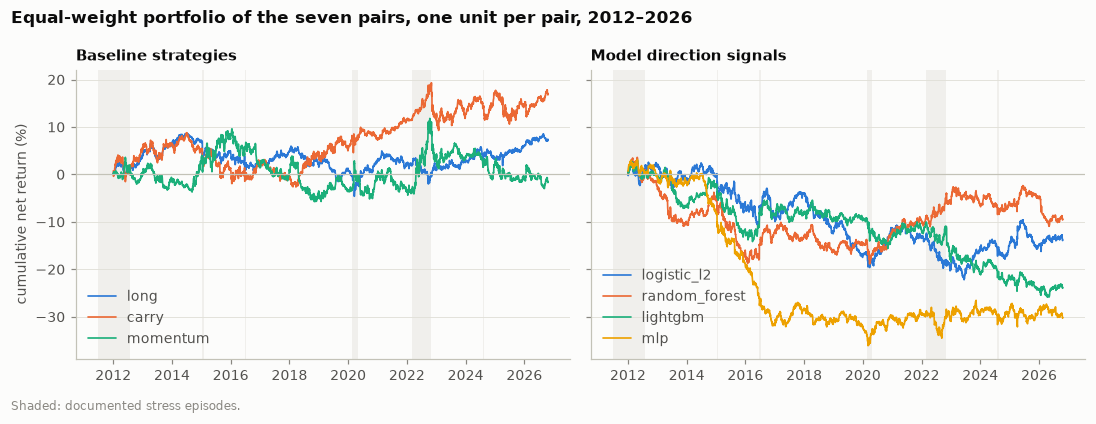

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
groups = [("Baseline strategies", BASELINE_SIGNALS), ("Model direction signals", MODEL_SIGNALS)]
port = daily[(daily.pair == "portfolio") & (daily.sizing == "unit")]
for ax, (title, signals) in zip(axes, groups):
    viz.shade_stress(ax, label=False, since="2012-01-01")
    for i, signal in enumerate(signals):
        rows = port[port.signal == signal].sort_values("date")
        ax.plot(rows.date, 100 * rows.net.cumsum(), color=viz.CATEGORICAL[i], label=signal, lw=1.1)
    ax.axhline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(title)
    ax.legend(loc="lower left")
axes[0].set_ylabel("cumulative net return (%)")
fig.suptitle("Equal-weight portfolio of the seven pairs, one unit per pair, 2012–2026", x=0.01,
             ha="left", fontweight="bold")
fig.text(0.01, -0.03, "Shaded: documented stress episodes.", color=viz.INK_MUTED, fontsize=8)
fig.tight_layout()
viz.save(fig, "backtest_cumulative")

PosixPath('./reports/figures/backtest_sharpe.png')

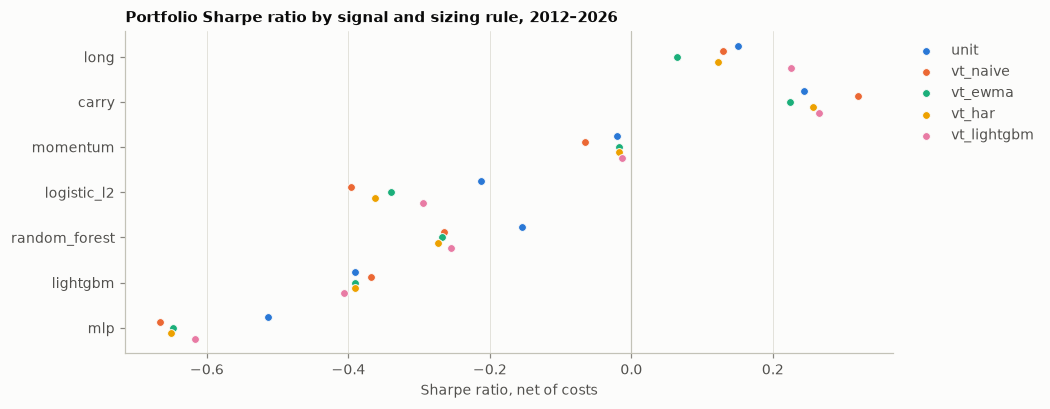

In [4]:
signals = BASELINE_SIGNALS + MODEL_SIGNALS
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, sizing in enumerate(SIZINGS):
    values = [portfolio.loc[(s, sizing), "sharpe"] for s in signals]
    ax.scatter(values, np.arange(len(signals)) + (i - 2) * 0.12, color=viz.CATEGORICAL[i],
               s=26, label=sizing, zorder=3, edgecolor=viz.SURFACE, linewidth=0.6)
ax.axvline(0, color=viz.BASELINE, lw=0.8)
ax.set_yticks(np.arange(len(signals)), signals)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Sharpe ratio, net of costs")
ax.set_title("Portfolio Sharpe ratio by signal and sizing rule, 2012–2026")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
viz.save(fig, "backtest_sharpe")

### Per pair

Sharpe ratios of the unit-sized strategies, net of costs.

In [5]:
per_pair = strategies[(strategies.pair != "portfolio") & (strategies.sizing == "unit")]
per_pair.pivot_table(index="pair", columns="signal", values="sharpe").loc[pairs, signals]

signal,long,carry,momentum,logistic_l2,random_forest,lightgbm,mlp
pair,,,,,,,
EURUSD,-0.222,0.241,0.093,0.236,-0.024,-0.324,0.003
GBPUSD,-0.133,-0.283,-0.050,0.256,0.006,0.081,0.085
USDJPY,0.692,0.692,0.299,-0.445,0.002,-0.054,-0.195
USDCHF,0.103,0.079,-0.328,-0.053,-0.374,-0.359,-0.048
AUDUSD,-0.194,0.206,0.034,-0.352,-0.102,-0.026,-0.499
USDCAD,0.314,-0.196,-0.115,0.321,0.193,-0.102,-0.159
NZDUSD,-0.127,0.067,-0.028,-0.451,-0.102,-0.432,-0.633


### By regime, stress episode and subperiod

Portfolio Sharpe ratios within each group of days (walk-forward Gaussian mixture regimes). Short episodes give very noisy Sharpe ratios; read them as the sign of the result.

In [6]:
show = breakdown[breakdown.sizing.isin(["unit", "vt_lightgbm"]) &
                 breakdown.signal.isin(["long", "carry", "momentum", "lightgbm", "mlp"])]
show.pivot_table(index=["dimension", "bucket"], columns=["signal", "sizing"], values="sharpe")

signal                           carry             lightgbm              \
sizing                            unit vt_lightgbm     unit vt_lightgbm   
dimension bucket                                                          
regime    calm                   0.307       0.343   -0.441      -0.433   
          turbulent              0.084       0.023   -0.265      -0.329   
stress    2022 tightening        2.275       2.886   -0.507      -0.971   
          Brexit referendum     -1.868      -1.572    3.571       4.275   
          COVID-19 crash        -0.585      -2.728   -1.816      -1.861   
          Euro area debt crisis  0.361       0.074    0.065      -0.289   
          Normal                 0.212       0.277   -0.429      -0.395   
          SNB removes franc cap -1.559      -3.521   -0.129      -1.552   
          Yen carry unwind      -4.054      -4.679   -0.790      -1.729   
subperiod 2012–2016              0.108      -0.001   -0.370      -0.336   
          2017–2021              0.450       0.385   -0.205      -0.233   
          2022–2026              0.214       0.399   -0.577      -0.646   

signal                            long                mlp              \
sizing                            unit vt_lightgbm   unit vt_lightgbm   
dimension bucket                                                        
regime    calm                   0.247       0.424 -0.837      -0.820   
          turbulent             -0.059      -0.320  0.236      -0.058   
stress    2022 tightening       -0.595      -0.221 -0.213      -0.554   
          Brexit referendum     -2.374      -2.160 -3.714      -2.896   
          COVID-19 crash        -1.199      -1.210  0.472      -0.574   
          Euro area debt crisis  0.734       0.306  0.143      -0.398   
          Normal                 0.255       0.290 -0.563      -0.622   
          SNB removes franc cap  0.641      -0.091 -2.970      -3.595   
          Yen carry unwind       1.506       2.231  3.038       2.854   
subperiod 2012–2016              0.103       0.207 -1.450      -1.506   
          2017–2021              0.027      -0.074  0.126      -0.168   
          2022–2026              0.329       0.566 -0.050      -0.092   

signal                          momentum              
sizing                              unit vt_lightgbm  
dimension bucket                                      
regime    calm                     0.091       0.086  
          turbulent               -0.278      -0.286  
stress    2022 tightening          2.152       2.653  
          Brexit referendum        2.689       1.981  
          COVID-19 crash           1.302       1.843  
          Euro area debt crisis    0.257       0.314  
          Normal                  -0.319      -0.285  
          SNB removes franc cap    6.096       6.790  
          Yen carry unwind        -2.352      -0.237  
subperiod 2012–2016                0.055       0.057  
          2017–2021               -0.206      -0.274  
          2022–2026                0.060       0.162

In [7]:
show.pivot_table(index=["dimension", "bucket"], columns="signal", values="days", aggfunc="max")

signal                           carry  lightgbm  long   mlp  momentum
dimension bucket                                                      
regime    calm                    2888      2888  2888  2888      2888
          turbulent                945       945   945   945       945
stress    2022 tightening          175       175   175   175       175
          Brexit referendum         17        17    17    17        17
          COVID-19 crash            51        51    51    51        51
          Euro area debt crisis    152       152   152   152       152
          Normal                  3415      3415  3415  3415      3415
          SNB removes franc cap     12        12    12    12        12
          Yen carry unwind          12        12    12    12        12
subperiod 2012–2016               1293      1293  1293  1293      1293
          2017–2021               1295      1295  1295  1295      1295
          2022–2026               1246      1246  1246  1246      1246

## Volatility targeting: do better volatility forecasts control risk better?

Always-long positions on each pair, so only the sizing differs. Each quarter the realised volatility of the position is compared with the 10% target. `tracking` is the root mean square of log(realised / target): 0 would be a perfect hit every quarter.

In [8]:
targeting.groupby("sizing")[["mean_realised_vol", "tracking", "quarters_above_1_5x"]].mean().loc[SIZINGS]

,mean_realised_vol,tracking,quarters_above_1_5x
sizing,,,
unit,0.083,0.389,0.024
vt_naive,0.105,0.123,0.010
vt_ewma,0.105,0.124,0.007
vt_har,0.096,0.132,0.002
vt_lightgbm,0.097,0.141,0.007


PosixPath('./reports/figures/backtest_risk_targeting.png')

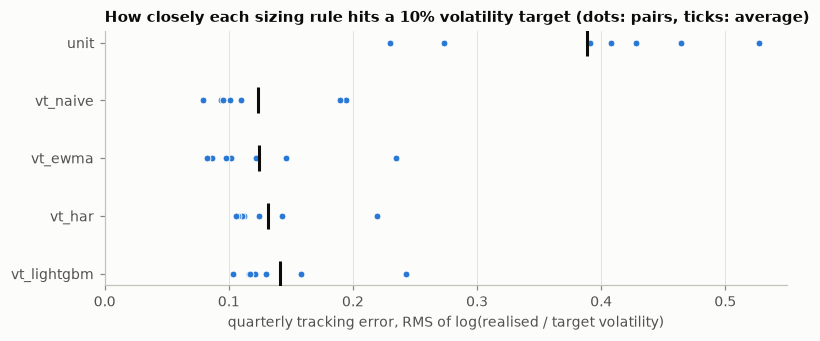

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
table = targeting.pivot(index="pair", columns="sizing", values="tracking").loc[pairs, SIZINGS]
for i, sizing in enumerate(SIZINGS):
    ax.scatter(table[sizing], np.full(len(pairs), i), color=viz.CATEGORICAL[0], s=20, zorder=3,
               edgecolor=viz.SURFACE, linewidth=0.6)
    ax.scatter(table[sizing].mean(), i, marker="|", s=300, color=viz.INK, linewidths=2, zorder=4)
ax.set_yticks(range(len(SIZINGS)), SIZINGS)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("quarterly tracking error, RMS of log(realised / target volatility)")
ax.set_title("How closely each sizing rule hits a 10% volatility target (dots: pairs, ticks: average)")
viz.save(fig, "backtest_risk_targeting")

## Value at Risk

Exceedance rates of the 99% Value at Risk (target 1%), averaged over pairs and both sides, and the share of the 14 pair-side tests each check passes (p ≥ 0.05). Both methods are compared on the same days, from early 2013, when the historical simulation has a year of past errors.

In [10]:
var["kupiec_ok"] = var.kupiec_p >= 0.05
var["independent_ok"] = var.christoffersen_p >= 0.05
summary = var.groupby(["model", "method"]).agg(rate=("rate", "mean"), kupiec_ok=("kupiec_ok", "mean"),
                                               independent_ok=("independent_ok", "mean")).unstack("method")
summary.sort_values(("rate", "normal"))

rate        kupiec_ok        independent_ok       
method                fhs normal       fhs normal            fhs normal
model                                                                  
mlp                 0.012  0.011     0.857  0.643          1.000  1.000
lstm                0.013  0.011     0.786  0.714          0.929  1.000
ridge_experts       0.012  0.011     0.929  0.643          1.000  1.000
lasso               0.012  0.011     0.786  0.714          1.000  1.000
ridge_regime        0.012  0.012     0.929  0.571          1.000  1.000
ridge               0.012  0.012     1.000  0.571          1.000  1.000
random_forest       0.012  0.012     0.929  0.714          1.000  1.000
baseline_har        0.012  0.012     0.929  0.714          1.000  1.000
lightgbm_regime     0.013  0.012     0.786  0.857          1.000  1.000
lightgbm_experts    0.013  0.012     0.643  0.714          1.000  1.000
lightgbm            0.013  0.012     0.929  0.643          1.000  1.000
knn                 0.013  0.012     0.714  0.714          0.929  0.929
baseline_garch      0.012  0.013     0.786  0.714          1.000  1.000
baseline_gjr_garch  0.012  0.013     0.929  0.643          1.000  1.000
baseline_ewma       0.012  0.017     0.786  0.214          1.000  1.000
baseline_naive      0.012  0.017     0.857  0.214          1.000  0.929

PosixPath('./reports/figures/risk_var_exceedances.png')

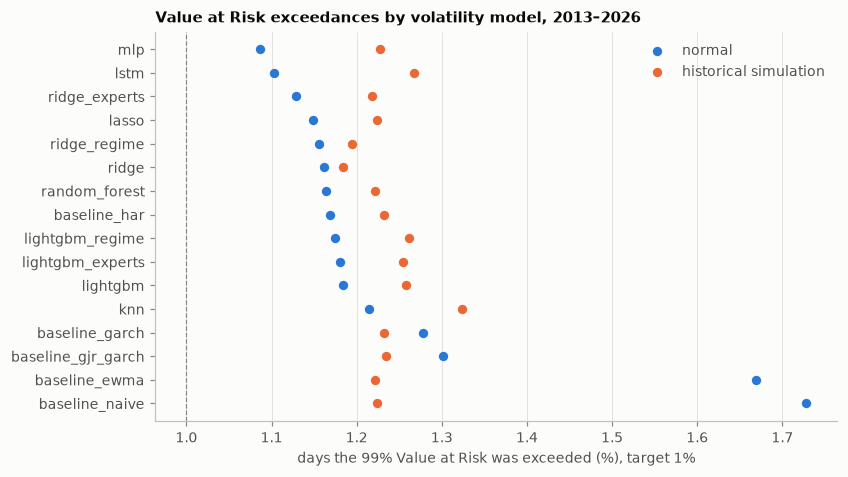

In [11]:
rates = var.groupby(["model", "method"])["rate"].mean().unstack("method")
order = rates["normal"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(order))
ax.scatter(100 * rates.loc[order, "normal"], y, color=viz.CATEGORICAL[0], s=26, label="normal", zorder=3)
ax.scatter(100 * rates.loc[order, "fhs"], y, color=viz.CATEGORICAL[1], s=26, label="historical simulation", zorder=3)
ax.axvline(1.0, color=viz.INK_MUTED, lw=0.8, ls="--")
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("days the 99% Value at Risk was exceeded (%), target 1%")
ax.set_title("Value at Risk exceedances by volatility model, 2013–2026")
ax.legend(loc="upper right")
viz.save(fig, "risk_var_exceedances")

## What drives LightGBM (SHAP)

Mean absolute SHAP value of each feature over every pair and test year: volatility in log variance units, direction in log-odds of an up day.

PosixPath('./reports/figures/shap_top_features.png')

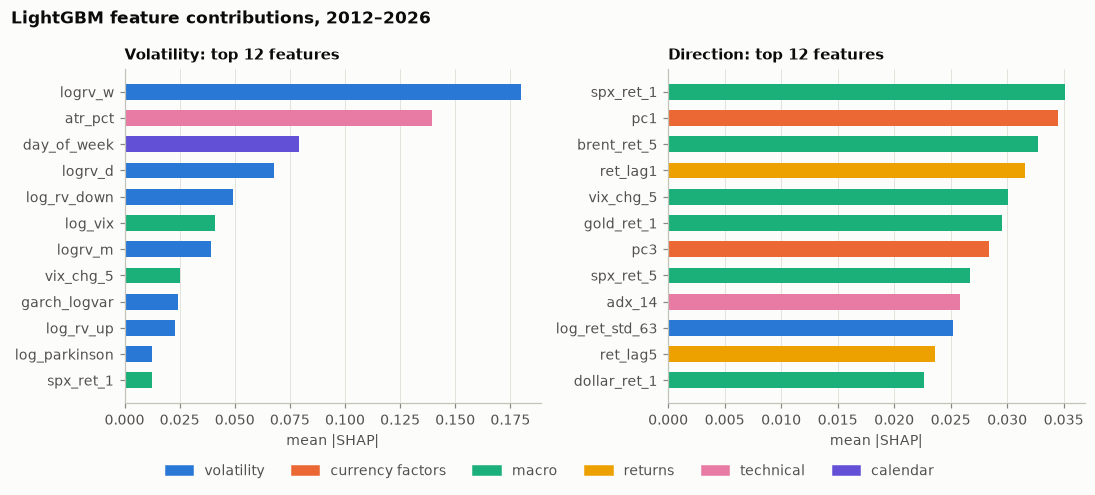

In [12]:
group_colors = {"volatility": viz.CATEGORICAL[0], "currency factors": viz.CATEGORICAL[1],
                "macro": viz.CATEGORICAL[2], "returns": viz.CATEGORICAL[3],
                "technical": viz.CATEGORICAL[4], "calendar": viz.CATEGORICAL[6]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, task in zip(axes, ["volatility", "direction"]):
    top = (shap[shap.task == task].groupby(["feature", "group"])["mean_abs_shap"].mean()
           .sort_values(ascending=False).head(12).reset_index())
    ax.barh(top.feature, top.mean_abs_shap, color=[group_colors[g] for g in top.group], height=0.6)
    ax.invert_yaxis()
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{task.capitalize()}: top 12 features")
    ax.set_xlabel("mean |SHAP|")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
fig.legend(handles, list(group_colors), loc="lower center", ncol=len(group_colors), bbox_to_anchor=(0.5, -0.06))
fig.suptitle("LightGBM feature contributions, 2012–2026", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "shap_top_features")

In [13]:
# Share of each feature group in the volatility model's total |SHAP|, year by year
vol = shap[shap.task == "volatility"]
shares = vol.groupby(["year", "group"])["mean_abs_shap"].sum().unstack()
(shares.div(shares.sum(axis=1), axis=0) * 100).round(1)

group,calendar,currency factors,macro,returns,technical,volatility
year,,,,,,
2012,6.7,3.0,12.9,9.8,12.3,55.2
2013,6.7,3.4,15.6,10.3,13.7,50.3
2014,7.2,1.9,11.8,7.0,17.4,54.8
2015,9.0,3.7,17.5,10.6,14.8,44.5
2016,9.3,4.5,18.8,12.7,15.4,39.4
2017,10.1,2.9,17.8,8.7,17.4,43.1
2018,10.1,2.3,15.9,8.2,20.2,43.2
2019,7.7,1.7,9.3,5.8,24.6,50.9
2020,8.3,2.4,16.1,7.2,22.3,43.7


## Findings

**The forecasting gains do not become trading profits.** No model's direction signal makes money. On the equal-weight portfolio the unit-sized signals of logistic regression, random forest, LightGBM and the MLP all lose after costs (Sharpe −0.16 to −0.51). Before costs they are roughly flat (gross Sharpe −0.28 to 0.10), so the losses are mostly costs: changing sides every few days turns over 140 to 180 units a year and costs about 1% a year, more than any edge they have. Doubling the spreads deepens the losses (LightGBM's Sharpe falls from −0.39 to −0.68). Trading only on each model's more confident days cuts turnover by about a fifth but leaves every model losing. The MLP's losses even pass a 5% significance test (t = −2.1), but with 55 strategies tested about three such results are expected by chance.

**Carry is the only strategy that earns anything, and it is not significant.** Holding the higher-yielding currency returns 1.1% a year at 4.5% volatility on the portfolio (Sharpe 0.25, t = 1.0) with almost no trading. It earns in calm regimes (Sharpe 0.31) but not in turbulent ones (0.08). It gained in the 2022 tightening and lost sharply in the 2024 yen carry unwind. Always long earns a Sharpe of 0.15 and 12-month momentum nothing (−0.02).

**Better volatility forecasts do not give better risk control.** Volatility targeting brings positions close to their 10% target whatever the forecast. Quarterly tracking error falls from 0.39 for unit positions to between 0.12 and 0.14 for every forecast, naive and EWMA included. HAR-RV and LightGBM, the best forecasts by QLIKE, do no better than EWMA at this horizon. Sharpe ratios move a little with the sizing rule: always long scores 0.06 with EWMA, 0.12 with HAR-RV and 0.23 with LightGBM. Differences that small are well inside the noise of a 15 year Sharpe ratio, whose standard error is about 0.26. The naive forecast trades the most (68 units a year against 11 for EWMA and 29 for LightGBM), which costs a little.

**Value at Risk is where better forecasts matter.** With normal quantiles, the naive and EWMA Value at Risk is beaten on 1.7% of days instead of 1%, failing the Kupiec test in 11 of 14 pair and side combinations. GARCH reaches 1.3%, and HAR-RV, LightGBM and the neural networks 1.1% to 1.2%. Filtered historical simulation rescues the weaker forecasts: every model lands between 1.2% and 1.3%, and the Kupiec test passes in 85% of cases against 62% for normal quantiles. Exceedances do not cluster for any model (the Christoffersen test passes in 99% of cases). The small excess over 1% that remains comes from tails fatter than even past errors show.

**What drives LightGBM.** For volatility the model relies on recent realized variance (the 5 day average most, then the latest day and the downside part), the average true range, the day of the week and the VIX. Volatility features carry 40% to 55% of the total contribution in every year, technical indicators (mostly the true range) 12% to 25% and calendar features 7% to 12%: realized variance differs systematically between weekdays. For direction the contributions are small and spread over many features (S&P 500, oil and gold returns, the dollar factor, recent returns) with none dominant, which is what a model fitting noise looks like.

**Answer to RQ4.** The volatility forecasting gains are real but small. They buy more reliable Value at Risk when it uses normal quantiles, but they do not improve risk targeting at a quarterly horizon or returns per unit of risk. The direction forecasts carry no trading value once costs are paid; the only positive result is the carry premium, which needs no forecast at all.